<h2 align="center">CIFAR-10 Classification: CNN vs AlexNet vs VGG vs ResNet</h2>



In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from matplotlib import pyplot as plt
import numpy as np

In [ ]:
# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

### Data Load

In [ ]:
from torchvision.datasets.utils import download_and_extract_archive

# Download the CIFAR-10 archive from an alternative server
download_and_extract_archive(
    url="https://zenodo.org/records/10089977/files/cifar-10-python.tar.gz",
    download_root="./data",
    filename="cifar-10-python.tar.gz",
    md5="c58f30108f718f92721af3b95e74349a",
)

100%|██████████| 170M/170M [01:57<00:00, 1.46MB/s]


In [ ]:
# Transformations
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# CIFAR-10 dataset
train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

In [ ]:
len(train_dataset), len(test_dataset)

(50000, 10000)

In [ ]:
batch_size = 100

# Data loaders
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

### Visualize a Few Images

In [ ]:
for i, (images, labels) in enumerate(train_loader):
    print(images.shape)
    print(labels.shape)
    break

torch.Size([100, 3, 32, 32])
torch.Size([100])


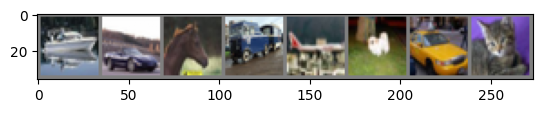

In [ ]:
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# show images
imshow(torchvision.utils.make_grid(images[:8]))

In [ ]:
classes = train_dataset.classes
classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

### Model 1 — Baseline CNN

Same model as last lab. Two conv layers: shallow, learns only simple edges/blobs, and the big FC head overfits.

![CIFAR-10 CNN architecture](https://raw.githubusercontent.com/sparshbansal-newton/images-used/main/cnn/cifar10_cnn.png)

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=(3,3), padding='same'),  # Output: (32, 32, 32)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2)),        # Output: (32, 16, 16)

            nn.Conv2d(32, 64, kernel_size=(3,3)),             # Output: (64, 14, 14)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))         # Output: (64, 7, 7)
        )
        self.fc_layers = nn.Sequential(
            nn.Flatten(),                                # Flatten to (64 * 7 * 7 = 3136)
            nn.Linear(64 * 7 * 7, 600),                  # Corrected input size
            nn.ReLU(),
            nn.Linear(600, 120),
            nn.ReLU(),
            nn.Linear(120, 10)
        )

    def forward(self, x):
        x = self.network(x)
        x = self.fc_layers(x)
        return x

### Model 2 — AlexNet (CIFAR version)

Deeper (5 conv layers), wider (up to 256-384 channels), and **Dropout** in the FC head to control overfitting (you added Dropout yourself last lab).

> The original AlexNet used 11×11 filters with stride 4 on 224×224 ImageNet images. On 32×32 CIFAR images that would shrink the image to ~7×7 after the first layer, so we use 3×3 filters instead. The key idea (deeper + wider + ReLU + Dropout) stays the same.

![AlexNet (CIFAR-10 version) architecture](https://raw.githubusercontent.com/sparshbansal-newton/images-used/main/cnn/alexnet_cifar10.png)

In [ ]:
class AlexNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=(3,3), padding='same'),   # Output: (64, 32, 32)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2)),         # Output: (64, 16, 16)

            nn.Conv2d(64, 192, kernel_size=(3,3), padding='same'), # Output: (192, 16, 16)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2)),         # Output: (192, 8, 8)

            nn.Conv2d(192, 384, kernel_size=(3,3), padding='same'),# Output: (384, 8, 8)
            nn.ReLU(),
            nn.Conv2d(384, 256, kernel_size=(3,3), padding='same'),# Output: (256, 8, 8)
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=(3,3), padding='same'),# Output: (256, 8, 8)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))          # Output: (256, 4, 4)
        )
        self.fc_layers = nn.Sequential(
            nn.Flatten(),                                # Flatten to (256 * 4 * 4 = 4096)
            nn.Dropout(0.5),
            nn.Linear(256 * 4 * 4, 4096),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(),
            nn.Linear(4096, 10)
        )

    def forward(self, x):
        x = self.network(x)
        x = self.fc_layers(x)
        return x

### Model 3 — VGG-style (with BatchNorm)

Only 3×3 convs, stacked uniformly with channels doubling 64→128→256→512, **BatchNorm** for stable training (same as last lab's exercise), and a tiny FC head (just one Linear).

> Two stacked 3×3 convs see the same area as one 5×5 conv but with fewer parameters.
> The original VGG had no BatchNorm (BN came later, in 2015) and a huge 3-layer FC head built for 224×224 images. We keep the core idea: small 3×3 filters, stacked deep.

![VGG-style (CIFAR-10) architecture](https://raw.githubusercontent.com/sparshbansal-newton/images-used/main/cnn/vgg_cifar10.png)

In [ ]:
class VGG(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=(3,3), padding='same'),    # (64, 32, 32)
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2)),          # (64, 16, 16)

            nn.Conv2d(64, 128, kernel_size=(3,3), padding='same'),  # (128, 16, 16)
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2)),          # (128, 8, 8)

            nn.Conv2d(128, 256, kernel_size=(3,3), padding='same'), # (256, 8, 8)
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=(3,3), padding='same'), # (256, 8, 8)
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2)),          # (256, 4, 4)

            nn.Conv2d(256, 512, kernel_size=(3,3), padding='same'), # (512, 4, 4)
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.Conv2d(512, 512, kernel_size=(3,3), padding='same'), # (512, 4, 4)
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2)),          # (512, 2, 2)

            nn.Conv2d(512, 512, kernel_size=(3,3), padding='same'), # (512, 2, 2)
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.Conv2d(512, 512, kernel_size=(3,3), padding='same'), # (512, 2, 2)
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))           # (512, 1, 1)
        )
        self.fc_layers = nn.Sequential(
            nn.Flatten(),                                # Flatten to (512 * 1 * 1 = 512)
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.network(x)
        x = self.fc_layers(x)
        return x

### Model 4 — ResNet-18

Deepest network. The **skip connection** (`out + x`) gives gradients a direct path back, so many layers stay trainable. `BasicBlock` is the repeating unit; `ResNet` stacks it.

> Why skip connections? Just stacking more plain layers makes a network *worse*, even on training data, because the gradient fades as it flows back through many layers. The skip path lets the signal and gradient bypass the block.
> Instead of flattening into a big FC head, ResNet uses **global average pooling** (`AdaptiveAvgPool2d`) → almost no FC parameters.

![ResNet-18 (CIFAR-10 version) architecture](https://raw.githubusercontent.com/sparshbansal-newton/images-used/main/cnn/resnet18_cifar10.png)

![ResNet BasicBlock](https://raw.githubusercontent.com/sparshbansal-newton/images-used/main/cnn/resnet_basic_block.png)

In [ ]:
class BasicBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, kernel_size=(3,3), stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, kernel_size=(3,3), stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.relu = nn.ReLU()

        # shortcut path: match shape when channels/size change
        self.shortcut = nn.Sequential()
        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=(1,1), stride=stride, bias=False),
                nn.BatchNorm2d(out_c)
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)     # skip connection
        out = self.relu(out)
        return out

In [ ]:
class ResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=(3,3), stride=1, padding=1, bias=False),  # (64, 32, 32)
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        self.network = nn.Sequential(
            BasicBlock(64, 64, stride=1),    BasicBlock(64, 64, stride=1),    # (64, 32, 32)
            BasicBlock(64, 128, stride=2),   BasicBlock(128, 128, stride=1),  # (128, 16, 16)
            BasicBlock(128, 256, stride=2),  BasicBlock(256, 256, stride=1),  # (256, 8, 8)
            BasicBlock(256, 512, stride=2),  BasicBlock(512, 512, stride=1)   # (512, 4, 4)
        )
        self.fc_layers = nn.Sequential(
            nn.AdaptiveAvgPool2d((1,1)),                 # (512, 1, 1)
            nn.Flatten(),                                # Flatten to 512
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.network(x)
        x = self.fc_layers(x)
        return x

### Train & Test Function

One function trains a model, tests it on train and test data, and saves the result in `results`.
We call it once for each model below.

In [ ]:
!pip install -q torchinfo
from torchinfo import summary

results = {}   # each call to train_and_test() adds one row here

In [ ]:
def train_and_test(model, num_epochs=10, learning_rate=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # Training loop
    total_step = len(train_loader)
    for epoch in range(num_epochs):
        model.train()
        for i, (images, labels) in enumerate(train_loader):
            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backward and optimize
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            if (i+1) % 100 == 0:
                print(f"Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{total_step}], Loss: {loss.item():.4f}")

    # Testing the model (on train and test data)
    model.eval()
    acc = {}
    with torch.no_grad():
        for name, loader in [('train', train_loader), ('test', test_loader)]:
            correct = 0
            total = 0
            for images, labels in loader:
                images = images.to(device)
                labels = labels.to(device)
                outputs = model(images)
                predicted = outputs.argmax(dim=1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
            acc[name] = 100 * correct / total

    print(f"Train accuracy: {acc['train']:.2f}%")
    print(f"Accuracy of the model on the 10000 test images: {acc['test']:.2f}%")

    # Save this model's result for the final comparison
    results[type(model).__name__] = {'Train Acc': acc['train'], 'Test Acc': acc['test']}
    return acc

### Train 1 — CNN

In [ ]:
model = CNN().to(device)
summary(model, input_size=(1, 3, 32, 32))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [1, 10]                   --
├─Sequential: 1-1                        [1, 64, 7, 7]             --
│    └─Conv2d: 2-1                       [1, 32, 32, 32]           896
│    └─ReLU: 2-2                         [1, 32, 32, 32]           --
│    └─MaxPool2d: 2-3                    [1, 32, 16, 16]           --
│    └─Conv2d: 2-4                       [1, 64, 14, 14]           18,496
│    └─ReLU: 2-5                         [1, 64, 14, 14]           --
│    └─MaxPool2d: 2-6                    [1, 64, 7, 7]             --
├─Sequential: 1-2                        [1, 10]                   --
│    └─Flatten: 2-7                      [1, 3136]                 --
│    └─Linear: 2-8                       [1, 600]                  1,882,200
│    └─ReLU: 2-9                         [1, 600]                  --
│    └─Linear: 2-10                      [1, 120]                  72,120

In [ ]:
train_and_test(model)

Epoch [1/10], Step [100/500], Loss: 1.5358
Epoch [1/10], Step [200/500], Loss: 1.2760
Epoch [1/10], Step [300/500], Loss: 1.3519
Epoch [1/10], Step [400/500], Loss: 1.1915
Epoch [1/10], Step [500/500], Loss: 1.0726
Epoch [2/10], Step [100/500], Loss: 0.9775
Epoch [2/10], Step [200/500], Loss: 1.1035
Epoch [2/10], Step [300/500], Loss: 0.8907
Epoch [2/10], Step [400/500], Loss: 1.1416
Epoch [2/10], Step [500/500], Loss: 0.8291
Epoch [3/10], Step [100/500], Loss: 0.8362
Epoch [3/10], Step [200/500], Loss: 0.6667
Epoch [3/10], Step [300/500], Loss: 0.9583
Epoch [3/10], Step [400/500], Loss: 0.7884
Epoch [3/10], Step [500/500], Loss: 0.7045
Epoch [4/10], Step [100/500], Loss: 0.6461
Epoch [4/10], Step [200/500], Loss: 0.6300
Epoch [4/10], Step [300/500], Loss: 0.5556
Epoch [4/10], Step [400/500], Loss: 0.4590
Epoch [4/10], Step [500/500], Loss: 0.4270
Epoch [5/10], Step [100/500], Loss: 0.4164
Epoch [5/10], Step [200/500], Loss: 0.4693
Epoch [5/10], Step [300/500], Loss: 0.5294
Epoch [5/10

{'train': 97.316, 'test': 71.76}

### Train 2 — AlexNet

In [ ]:
model = AlexNet().to(device)
summary(model, input_size=(1, 3, 32, 32))

Layer (type:depth-idx)                   Output Shape              Param #
AlexNet                                  [1, 10]                   --
├─Sequential: 1-1                        [1, 256, 4, 4]            --
│    └─Conv2d: 2-1                       [1, 64, 32, 32]           1,792
│    └─ReLU: 2-2                         [1, 64, 32, 32]           --
│    └─MaxPool2d: 2-3                    [1, 64, 16, 16]           --
│    └─Conv2d: 2-4                       [1, 192, 16, 16]          110,784
│    └─ReLU: 2-5                         [1, 192, 16, 16]          --
│    └─MaxPool2d: 2-6                    [1, 192, 8, 8]            --
│    └─Conv2d: 2-7                       [1, 384, 8, 8]            663,936
│    └─ReLU: 2-8                         [1, 384, 8, 8]            --
│    └─Conv2d: 2-9                       [1, 256, 8, 8]            884,992
│    └─ReLU: 2-10                        [1, 256, 8, 8]            --
│    └─Conv2d: 2-11                      [1, 256, 8, 8]            

In [ ]:
train_and_test(model)

Epoch [1/10], Step [100/500], Loss: 1.7841
Epoch [1/10], Step [200/500], Loss: 1.4093
Epoch [1/10], Step [300/500], Loss: 1.4982
Epoch [1/10], Step [400/500], Loss: 1.3157
Epoch [1/10], Step [500/500], Loss: 1.3402
Epoch [2/10], Step [100/500], Loss: 1.1886
Epoch [2/10], Step [200/500], Loss: 1.3561
Epoch [2/10], Step [300/500], Loss: 1.3649
Epoch [2/10], Step [400/500], Loss: 1.0876
Epoch [2/10], Step [500/500], Loss: 1.2939
Epoch [3/10], Step [100/500], Loss: 0.9614
Epoch [3/10], Step [200/500], Loss: 0.9961
Epoch [3/10], Step [300/500], Loss: 0.9419
Epoch [3/10], Step [400/500], Loss: 0.9515
Epoch [3/10], Step [500/500], Loss: 1.1208
Epoch [4/10], Step [100/500], Loss: 1.0741
Epoch [4/10], Step [200/500], Loss: 0.9610
Epoch [4/10], Step [300/500], Loss: 1.1819
Epoch [4/10], Step [400/500], Loss: 0.9207
Epoch [4/10], Step [500/500], Loss: 0.8937
Epoch [5/10], Step [100/500], Loss: 0.6933
Epoch [5/10], Step [200/500], Loss: 0.7168
Epoch [5/10], Step [300/500], Loss: 0.9288
Epoch [5/10

{'train': 85.874, 'test': 76.14}

### Train 3 — VGG

In [ ]:
model = VGG().to(device)
summary(model, input_size=(1, 3, 32, 32))

Layer (type:depth-idx)                   Output Shape              Param #
VGG                                      [1, 10]                   --
├─Sequential: 1-1                        [1, 512, 1, 1]            --
│    └─Conv2d: 2-1                       [1, 64, 32, 32]           1,792
│    └─BatchNorm2d: 2-2                  [1, 64, 32, 32]           128
│    └─ReLU: 2-3                         [1, 64, 32, 32]           --
│    └─MaxPool2d: 2-4                    [1, 64, 16, 16]           --
│    └─Conv2d: 2-5                       [1, 128, 16, 16]          73,856
│    └─BatchNorm2d: 2-6                  [1, 128, 16, 16]          256
│    └─ReLU: 2-7                         [1, 128, 16, 16]          --
│    └─MaxPool2d: 2-8                    [1, 128, 8, 8]            --
│    └─Conv2d: 2-9                       [1, 256, 8, 8]            295,168
│    └─BatchNorm2d: 2-10                 [1, 256, 8, 8]            512
│    └─ReLU: 2-11                        [1, 256, 8, 8]            --


In [ ]:
train_and_test(model)

Epoch [1/10], Step [100/500], Loss: 1.5488
Epoch [1/10], Step [200/500], Loss: 1.2255
Epoch [1/10], Step [300/500], Loss: 1.2736
Epoch [1/10], Step [400/500], Loss: 0.9308
Epoch [1/10], Step [500/500], Loss: 0.9983
Epoch [2/10], Step [100/500], Loss: 0.7809
Epoch [2/10], Step [200/500], Loss: 0.7440
Epoch [2/10], Step [300/500], Loss: 0.6783
Epoch [2/10], Step [400/500], Loss: 0.5936
Epoch [2/10], Step [500/500], Loss: 0.6506
Epoch [3/10], Step [100/500], Loss: 0.6804
Epoch [3/10], Step [200/500], Loss: 0.4936
Epoch [3/10], Step [300/500], Loss: 0.4817
Epoch [3/10], Step [400/500], Loss: 0.6999
Epoch [3/10], Step [500/500], Loss: 0.6634
Epoch [4/10], Step [100/500], Loss: 0.4121
Epoch [4/10], Step [200/500], Loss: 0.6112
Epoch [4/10], Step [300/500], Loss: 0.4552
Epoch [4/10], Step [400/500], Loss: 0.4266
Epoch [4/10], Step [500/500], Loss: 0.4882
Epoch [5/10], Step [100/500], Loss: 0.4512
Epoch [5/10], Step [200/500], Loss: 0.4912
Epoch [5/10], Step [300/500], Loss: 0.4242
Epoch [5/10

{'train': 96.786, 'test': 81.8}

### Train 4 — ResNet

In [ ]:
model = ResNet().to(device)
summary(model, input_size=(1, 3, 32, 32))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 10]                   --
├─Sequential: 1-1                        [1, 64, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 64, 32, 32]           1,728
│    └─BatchNorm2d: 2-2                  [1, 64, 32, 32]           128
│    └─ReLU: 2-3                         [1, 64, 32, 32]           --
├─Sequential: 1-2                        [1, 512, 4, 4]            --
│    └─BasicBlock: 2-4                   [1, 64, 32, 32]           --
│    │    └─Conv2d: 3-1                  [1, 64, 32, 32]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 32, 32]           128
│    │    └─ReLU: 3-3                    [1, 64, 32, 32]           --
│    │    └─Conv2d: 3-4                  [1, 64, 32, 32]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 32, 32]           128
│    │    └─Sequential: 3-6              [1, 64, 32, 32]           --
│

In [ ]:
train_and_test(model)

Epoch [1/10], Step [100/500], Loss: 1.7298
Epoch [1/10], Step [200/500], Loss: 1.6210
Epoch [1/10], Step [300/500], Loss: 1.2011
Epoch [1/10], Step [400/500], Loss: 1.0631
Epoch [1/10], Step [500/500], Loss: 0.9358
Epoch [2/10], Step [100/500], Loss: 0.9370
Epoch [2/10], Step [200/500], Loss: 0.7415
Epoch [2/10], Step [300/500], Loss: 1.0808
Epoch [2/10], Step [400/500], Loss: 0.7408
Epoch [2/10], Step [500/500], Loss: 0.6189
Epoch [3/10], Step [100/500], Loss: 0.7126
Epoch [3/10], Step [200/500], Loss: 0.8051
Epoch [3/10], Step [300/500], Loss: 0.7190
Epoch [3/10], Step [400/500], Loss: 0.5983
Epoch [3/10], Step [500/500], Loss: 0.7033
Epoch [4/10], Step [100/500], Loss: 0.3050
Epoch [4/10], Step [200/500], Loss: 0.5519
Epoch [4/10], Step [300/500], Loss: 0.4226
Epoch [4/10], Step [400/500], Loss: 0.4312
Epoch [4/10], Step [500/500], Loss: 0.4819
Epoch [5/10], Step [100/500], Loss: 0.4423
Epoch [5/10], Step [200/500], Loss: 0.4054
Epoch [5/10], Step [300/500], Loss: 0.3024
Epoch [5/10

{'train': 96.962, 'test': 82.95}

### Comparison

         Train Acc  Test Acc
CNN          97.32     71.76
AlexNet      85.87     76.14
VGG          96.79     81.80
ResNet       96.96     82.95


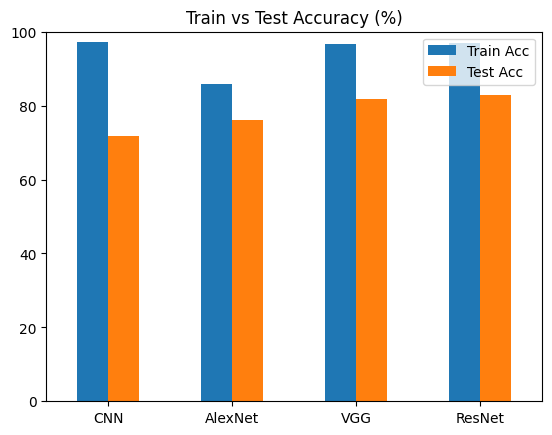

In [ ]:
import pandas as pd

df = pd.DataFrame(results).T
print(df.round(2))
df.plot.bar(rot=0, ylim=(0, 100), title='Train vs Test Accuracy (%)')
plt.show()

### ✅ Conclusion

| Model | Total params | FC params | Idea |
|---|---|---|---|
| CNN | 1.97M | 1.96M (99%) | 2 convs + big FC head |
| AlexNet | 35.9M | 33.6M (94%) | deeper + wider + Dropout |
| VGG-style | 9.2M | 0.005M | stacked 3×3 convs + BatchNorm |
| ResNet-18 | 11.2M | 0.005M | skip connections + global avg pool |

- **AlexNet:** deeper + wider + Dropout. Better features, but most parameters still sit in a huge FC head.
- **VGG:** only 3×3 convs + BatchNorm. Parameters move into the conv layers; tiny FC head.
- **ResNet:** skip connections (`out + x`) let very deep networks train; global average pooling replaces the big FC head.
- **Trend:** parameters move from FC layers into conv layers, networks get deeper, and test accuracy goes up.